使用 CNN 实现 MNIST 手写数字体识别

基于[torch09_CNN03_MNIST.ipynb](llm02_ml_dl/02_pytorch/torch09_CNN/torch09_CNN03_MNIST.ipynb) 的基础上增加 TensorBoard 相关代码

# PyTorch TensorBoard：可视化训练过程从入门到实践

TensorBoard 是 TensorFlow 生态中发展起来的训练可视化工具，PyTorch 可通过 torch.utils.tensorboard.SummaryWriter 写入兼容的 event 日志文件。训练脚本负责记录数据，TensorBoard 读取日志并在浏览器中展示曲线、图像、模型图、参数分布等信息。

它不负责训练模型，也不会自动理解 loss。开发者需要明确记录什么指标、在哪个 step 记录、训练集与验证集如何区分。好的可视化能帮助回答：模型是否在学习、是否过拟合、梯度是否异常、不同实验哪个更好。

本文从原理和安装开始，逐步讲解标量、训练/验证曲线、图像、模型计算图、直方图、超参数实验、日志管理、检查点和排错。所有代码示例均配有概念说明，主线使用简单 MLP 分类任务。示例适用于现代 PyTorch 2.x；TensorBoard 相关包需另行安装。


# TensorBoard 基础

In [26]:
import torch
import tensorboard
from torch.utils.tensorboard import SummaryWriter

print("torch:", torch.__version__)
print("tensorboard:", tensorboard.__version__)
print(SummaryWriter)

torch: 2.14.1
tensorboard: 2.21.0
<class 'torch.utils.tensorboard.writer.SummaryWriter'>


In [19]:
from torch.utils.tensorboard import SummaryWriter
logdir = "../data/logs/runs/mnist"
writer = SummaryWriter(log_dir=logdir)
writer.add_scalar("loss/train", 0.82, global_step=1)
writer.add_scalar("loss/valid", 0.91, global_step=1)
writer.close()

In [20]:
## 2. TensorBoard 的基本组成
# 核心组件有三部分：训练代码中的 SummaryWriter、磁盘上的 event 文件、浏览器里的 TensorBoard 服务。
# Writer 将 summary 数据异步写入日志目录；TensorBoard 服务读取目录并展示数据。日志目录不是模型 checkpoint，也不是训练代码本身。
from pathlib import Path
from torch.utils.tensorboard import SummaryWriter

log_dir = Path("../data/logs/runs/first_experiment")
writer = SummaryWriter(log_dir=log_dir)
writer.add_scalar("demo/value", 1.0, 0)
writer.flush()  # 立即把缓冲数据写出
writer.close()
print(log_dir.resolve())

/Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/data/logs/runs/first_experiment


In [32]:
# SummaryWriter 接收日志目录，可选 flush_secs、max_queue、filename_suffix 等参数。
# 日志通常放在 runs/项目名/实验名；不同实验用不同子目录，避免混到同一条曲线。
log_dir = Path("../data/logs/runs/project1/exper1")
writer = SummaryWriter(log_dir=log_dir, flush_secs=30)
# global_step s是全局训练步数，同一个指标的 global_step 变化大小必须相同，即 可以认为global_step是每一个点的间隔，global_step每次加1
losses = torch.randn(30)
losses_train = torch.randn(30)
losses_valid = torch.randn(30)
losses_test = torch.randn(30)
for index, loss in enumerate(losses):
    # 记录标量使用的是 add_scalar
    # 标量是最常见的训练信息，如 loss、accuracy、learning rate。
    # add_scalar(tag, scalar_value, global_step) 的 tag 是图表名称/分组路径，value 是单个数值，step 是横轴位置。
    writer.add_scalar("demo/loss", loss, global_step=index)
    # 在 tag 中，可以使用 / 来对数据进行分组
    writer.add_scalar("loss/train", losses_train[index], global_step=index)
    writer.add_scalar("loss/valid", losses_valid[index], global_step=index)
    writer.add_scalar("loss/test", losses_test[index], global_step=index)
writer.flush() # 不要频繁的调用 flush，否则增加IO开销
writer.close()
print(log_dir.resolve())


# 传入 Tensor 时先 detach 并转为 Python 数值，避免日志操作无意间保留计算图或传入多元素 Tensor。

loss = torch.tensor(0.42, requires_grad=True)
writer.add_scalar("loss/example", loss.detach().item(), global_step=1)

/Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/data/logs/runs/project1/exper1


In [ ]:
## 5. 启动 TensorBoard 查看日志
# 训练完成或运行中，从项目目录启动 TensorBoard，并让 logdir 指向 event 文件所在目录的父级。Web 服务默认端口通常为 6006。
# uv run tensorboard --logdir ./data/logs/runs --port 6006
# 随后访问：http://localhost:6006/


In [40]:
## 7. Global step 的含义
# global_step 应随训练进度单调增加。
#   若按 batch 写入，常用 epoch * steps_per_epoch + batch_index；
#   若按 epoch 写入，直接使用 epoch 编号。
# step 重复或回退可能导致图表点覆盖、重排或显示异常。
# 可以简单理解为 global_step 就是图像的 x 轴，x 轴要均匀稳定的增加

# 在使用过程中通常按照 epoch 写入

# 定义 sw
log_dir = Path("../data/logs/runs/project2/epoch")
writer = SummaryWriter(log_dir=log_dir, flush_secs=30)
epochs = 100
train_losses = torch.randn(epochs)
valid_losses = torch.randn(epochs)
for epoch in range(epochs):
    train_loss = train_losses[epoch]
    valid_loss = valid_losses[epoch]
    writer.add_scalar("loss/train", train_loss.detach().item(), global_step=epoch)
    writer.add_scalar("loss/valid", valid_loss.detach().item(), global_step=epoch)

    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch + 1}, train_loss: {train_loss:.4f}, valid_loss: {valid_loss:.4f}")

writer.flush()
writer.close()


epoch: 10, train_loss: -0.4043, valid_loss: -1.0007
epoch: 20, train_loss: -0.8563, valid_loss: 0.7755
epoch: 30, train_loss: 2.0825, valid_loss: 1.0242
epoch: 40, train_loss: 0.2587, valid_loss: -0.0654
epoch: 50, train_loss: 0.9145, valid_loss: 0.5181
epoch: 60, train_loss: 0.3542, valid_loss: -0.9315
epoch: 70, train_loss: -0.4559, valid_loss: 0.4280
epoch: 80, train_loss: 0.9057, valid_loss: 0.7349
epoch: 90, train_loss: 0.6184, valid_loss: 0.1080
epoch: 100, train_loss: -0.1452, valid_loss: -1.0128


In [ ]:
## 8. 需要记录哪些指标
# 分类任务通常记录 train/validation loss、accuracy、learning rate；不平衡分类还应记录 precision、recall、F1 或 PR-AUC。
# 回归任务可记录 MAE、RMSE；
# 生成任务可记录 token loss、吞吐量等。
# 记录指标应围绕诊断问题，不要因能记录而无限堆指标。




In [53]:
# summaryWriter 输出图片
image = torch.rand((3, 28, 28), )
image2 = torch.rand((3, 28, 28), )

log_dir = Path("../data/logs/runs/mnist/image2")
writer = SummaryWriter(log_dir=log_dir, flush_secs=30)
# image 的形状是[C, H, W] C表示通道数
writer.add_image("mnist/test-image2", image, global_step=0)
writer.add_image("mnist/test-image2", image2, global_step=1)
writer.flush()
writer.close()

# # 批量图像可用 add_images，输入常为 NCHW。TensorBoard 也可用 add_image 写入 torchvision.make_grid 生成的拼图，便于一次查看一批样本。


In [59]:
## 14. 记录模型计算图 add_graph
import torch.nn as nn
from pathlib import Path
from datetime import datetime
model = nn.Linear(28 * 28, 10)
image = torch.rand((3, 28, 28), )
print(image.shape)
image = image.reshape(3, -1)
print(image.shape)
logdir = Path("../data/logs/runs") / "linear" / datetime.now().strftime("%Y%m%d-%H%M%S")
writer = SummaryWriter(log_dir=logdir)
writer.add_graph(model, image)
writer.flush()
writer.close()


torch.Size([3, 28, 28])
torch.Size([3, 784])


In [62]:
## 16. 记录文本 add_text
# add_text 可写入实验说明、配置摘要或少量样例。它支持 Markdown 展示，适合记录可读信息；不要写入隐私文本、密钥或敏感数据。
logdir = Path("../data/logs/runs") / "add_text" / datetime.now().strftime("%Y%m%d-%H%M%S")
writer = SummaryWriter(log_dir=logdir)
writer.add_text("experiment/notes", "MLP baseline with AdamW", global_step=0)
writer.add_text("experiment/config", "| key | value |\\n|---|---|\\n| lr | 0.01 |", 0)

# 可记录模型配置、数据版本和随机种子，使日志目录更具可追溯性。
config = {"seed": 23, "batch_size": 64, "lr": 0.01, "hidden": 32}
writer.add_text("experiment/config", str(config), global_step=0)

writer.flush()
writer.close()


In [63]:
## 20. 关闭 writer 和异常安全
# Writer 会缓冲数据；close 会刷新并释放资源。训练中断或异常时，建议用 try/finally 或上下文管理确保关闭。仅靠进程退出可能丢失最后一段尚未 flush 的事件。
writer = SummaryWriter(log_dir=logdir)
try:
    # 执行训练 ...
    writer.add_scalar("loss/example", 1.0, global_step=1)
finally:
    writer.close()

# 短脚本也可以使用 with
with SummaryWriter(log_dir=logdir) as writer:
    writer.add_scalar("loss/example", 2.0, global_step=2)


# 以下使用 MNIST 数据集来训练 CNN 网络实现图像分类，并且在这个基础上加入 TensorBoard 以达到训练数据可视化

In [41]:
import copy
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from torch.utils.tensorboard import SummaryWriter

torch.manual_seed(23)

In [2]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: mps


In [4]:
# 1、加载数据集
transform = transforms.Compose([transforms.ToTensor()])
full_train_set = datasets.MNIST("../data/dl", train=True, download=True, transform=transform)
test_set = datasets.MNIST("../data/dl", train=False, download=True, transform=transform)

train_size = int(len(full_train_set)*0.9)
valid_size = len(full_train_set) - train_size
train_set, valid_set = random_split(full_train_set, [train_size, valid_size], generator=torch.Generator().manual_seed(23))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

print(f"train_set size: {len(train_set)}, valid_set size: {len(valid_set)}, test_set size: {len(test_set)}")

train_set size: 54000, valid_set size: 6000, test_set size: 10000


torch.Size([1, 28, 28]) 2


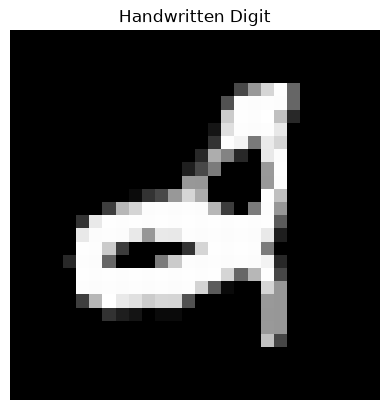

In [47]:
# 简单的查看一个图片
image, y = next(iter(train_set))
print(image.shape, y)
# 显示灰度图像
plt.imshow(image.squeeze(), cmap="gray")

plt.title("Handwritten Digit")
plt.axis("off")
plt.show()

In [6]:
# 2、定义模型
class MNISTCNN(nn.Module):
    def __init__(self, num_classes =  10):
        super(MNISTCNN, self).__init__()
        # 输入图像 [1, 28, 28]，1表示一个通道，是 28 * 28 的图像
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5, padding=2),
            nn.BatchNorm2d(num_features=16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, padding=2),
            nn.BatchNorm2d(num_features=32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5, padding=2),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=64 * 3 * 3, out_features=num_classes),
        )
    def forward(self, x):
        x = self.features(x)
        # print(x.shape) # 输出 torch.Size([1, 64, 3, 3]) ，故nn.Linear里面图像的长宽都是3
        return self.classifier(x)

tmc = MNISTCNN()
x = torch.randn(1, 1, 28, 28)
y = tmc(x)
print(y.shape)

torch.Size([1, 10])


In [42]:
# 训练阶段
model = MNISTCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.01,momentum=0.9,weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)

best_accuracy = -1.0
best_model_state_dict = None
last_train_loss = None

train_losses, valid_losses = [], []
train_accuracies, valid_accuracies = [], []

# Early Stopping 参数
patience = 5
min_delta = 1e-4
early_stop_counter = 0
best_valid_loss = float("inf")

# 增加 SummaryWriter
logdir = Path("../data/logs/runs/mnist/cnn")
summary_writer = SummaryWriter(log_dir=logdir, flush_secs=30)

epochs = 30
for epoch in range(epochs):

    # 训练
    model.train()
    train_sample = 0
    train_loss_sum = 0
    train_correct = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logist = model(images)
        loss = criterion(logist, labels)
        loss.backward()
        optimizer.step()

        # 累计损失
        train_size = images.shape[0]
        train_sample += train_size
        train_loss_sum += loss.item() * train_size

        # 累计正确数
        proba = logist.argmax(dim=1)
        train_correct += proba.eq(labels).sum().item()

    train_loss = train_loss_sum / train_sample
    train_accuracy = train_correct / train_sample
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    last_train_loss = train_loss


    # 验证
    model.eval()
    valid_sample = 0
    valid_loss_sum = 0
    valid_correct = 0
    with torch.inference_mode():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)
            logist = model(images)
            loss = criterion(logist, labels)
            valid_size = images.shape[0]
            valid_sample += valid_size
            valid_loss_sum += loss.item() * valid_size
            proba = logist.argmax(dim=1)
            valid_correct += proba.eq(labels).sum().item()

    valid_loss = valid_loss_sum / valid_sample
    valid_accuracy = valid_correct / valid_sample
    valid_losses.append(valid_loss)
    valid_accuracies.append(valid_accuracy)

    # 保存最佳模型参数
    if valid_accuracy > best_accuracy:
        best_accuracy = valid_accuracy
        best_model_state_dict = copy.deepcopy(model.state_dict())

    # 修改学习率
    scheduler.step()
    current_lr = optimizer.param_groups[0]["lr"]

    # 训练数据输出
    if (epoch + 1) % 10 == 0:
        print(f"epoch: {epoch+1}, current_lr: {current_lr:.4f}, train_loss: {train_loss:.4f}, train_accuracy: {train_accuracy:.4f}, valid_accuracy: {valid_accuracy:.4f}, valid_loss: {valid_loss:.4f}, valid_accuracy: {valid_accuracy:.4f}")


    # 将每个 epoch 的训练数据记录到 summary_writer 里面
    summary_writer.add_scalar("loss/train", train_loss, epoch)
    summary_writer.add_scalar("loss/valid", valid_loss, epoch)
    summary_writer.add_scalar("accuracy/train", train_accuracy, epoch)
    summary_writer.add_scalar("accuracy/valid", valid_accuracy, epoch)
    summary_writer.add_scalar("learning_rate", current_lr, epoch)

    # Early Stopping
    if current_lr < 1e-4:
        print(f"Epoch {epoch + 1} finished successfully, reason: lr = {current_lr} will be not update")
        break
    # Early Stopping
    if valid_loss < best_valid_loss - min_delta:
        best_valid_loss = valid_loss
        early_stop_counter = 0
    else:
        early_stop_counter += 1

    if early_stop_counter >= patience:
        print(
            f"Early Stopping: "
            f"valid_loss 连续 {patience} 个 Epoch 没有明显改善"
        )
        break

# 保存最佳模型参数
torch.save(best_model_state_dict, "../data/output/MNISTCNN_best_model_state_dict.pth")
print(f"best_accuracy: {best_accuracy}")

# 刷新 summary_writer
summary_writer.flush()
summary_writer.close()


epoch: 10, current_lr: 0.0100, train_loss: 0.0046, train_accuracy: 0.9996, valid_accuracy: 0.9918, valid_loss: 0.0254, valid_accuracy: 0.9918
epoch: 20, current_lr: 0.0010, train_loss: 0.0019, train_accuracy: 1.0000, valid_accuracy: 0.9930, valid_loss: 0.0220, valid_accuracy: 0.9930
Early Stopping: valid_loss 连续 5 个 Epoch 没有明显改善
best_accuracy: 0.9935


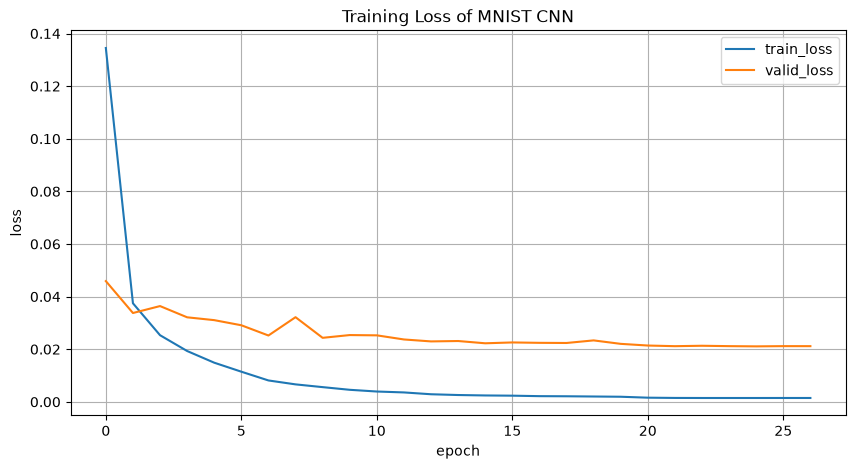

In [43]:
# 训练过程可视化
# loss
plt.figure(figsize=(10,5))
plt.plot(train_losses, label="train_loss")
plt.plot(valid_losses, label="valid_loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Training Loss of MNIST CNN")
plt.legend()
plt.grid(True)
plt.show()

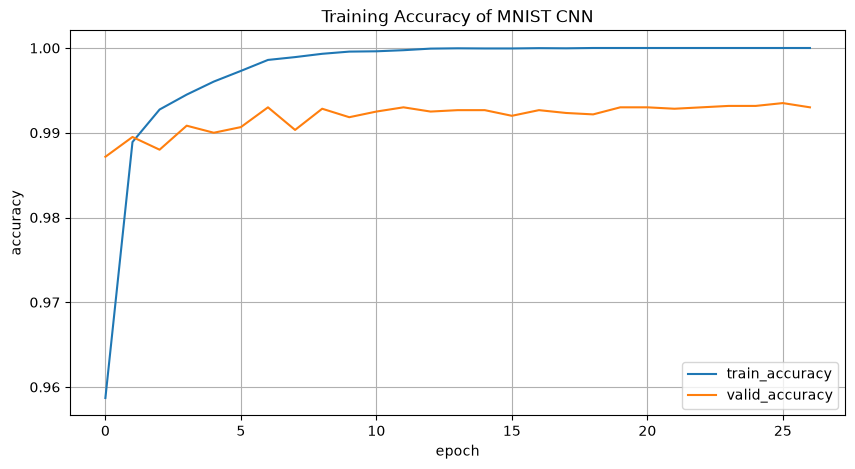

In [44]:
# acc
plt.figure(figsize=(10,5))
plt.plot(train_accuracies, label="train_accuracy")
plt.plot(valid_accuracies, label="valid_accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Training Accuracy of MNIST CNN")
plt.legend()
plt.grid(True)
plt.show()

correct: 9935, total: 10000, Accuracy: 0.9935


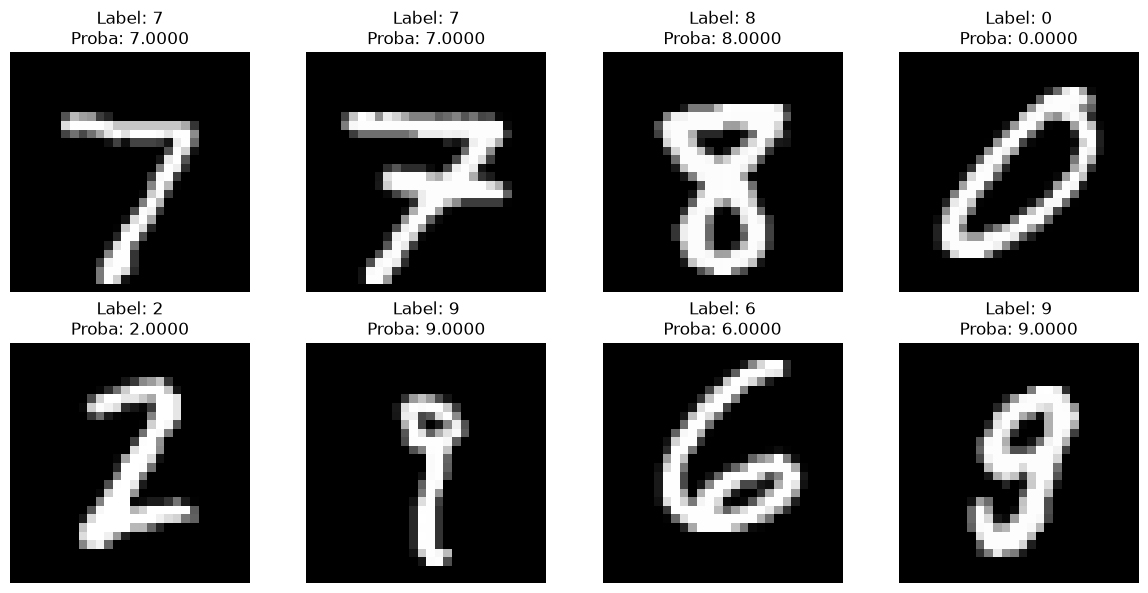

In [12]:
# 测试阶段

# 一般情况下，测试阶段都是要加载训练阶段保存的最佳模型，而不能直接使用训练阶段继承下来的模型，以为训练阶段的模型是最后一次调参的模型，并不是最优的模型
best_model = MNISTCNN().to(device)
best_model_state_dict = torch.load("../data/output/MNISTCNN_best_model_state_dict.pth", map_location="cpu", weights_only=True)
best_model.load_state_dict(best_model_state_dict)
best_model.eval()

correct, total = 0, 0

# 保存部分图片的数据、真实标签、预测标签
test_pred_data = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logist = best_model(images)
        proba = logist.argmax(dim=1)
        correct += proba.eq(labels).sum().item()
        total += images.shape[0]
        if len(test_pred_data) < 8:
            item = {
                "image": images[0],
                "label": labels[0],
                "proba": proba[0],
            }
            test_pred_data.append(item)

print(f"correct: {correct}, total: {total}, Accuracy: {correct / total:.4f}")

# 测试数据可视化
# 创建 2 行 4 列的画布
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

# 将二维 axes 转换为一维，方便遍历
axes = axes.flatten()

for i, item in enumerate(test_pred_data):
    image = item["image"]
    label = item["label"]
    proba = item["proba"]

    # 显示灰度图像
    axes[i].imshow(image.to(torch.device("cpu")).squeeze(), cmap="gray")

    # 显示标题
    axes[i].set_title(
        f"Label: {label}\nProba: {proba:.4f}"
    )

    # 隐藏坐标轴
    axes[i].axis("off")

plt.tight_layout()
plt.show()

